# Fruit Ripeness Grading via Ordinal Regression — ResNet152

## Dataset-ready classification notebook

This notebook is configured specifically for **banana ripeness classification** using the Mendeley **BananaID** dataset. The dataset contains four ordered ripeness stages: **Unripe → Half-ripe → Ripe → Overripe**, with 1,960 original ripeness images. The dataset is designed for image classification and provides a natural ordinal target.

The experiment compares:

1. **Standard multiclass classification** using softmax + categorical cross-entropy.
2. **Ordinal regression** using cumulative threshold outputs and an ordinal binary cross-entropy loss.

Both models use the same **ResNet152 architecture, image preprocessing, train/validation/test split, and training budget** so that the comparison is meaningful.

Dataset source: Mendeley Data, *BananaID: An image dataset of banana varieties and ripeness stages in Indonesia designed for classification*.


## Expected dataset structure

Download the **original ripeness-classification images** from the BananaID dataset and place them under `./dataset`.

The loader below is flexible and searches recursively, so the exact nesting does not matter as long as folders can be identified by these class names:

```text
dataset/
├── Unripe/
├── Half-ripe/
├── Ripe/
└── Overripe/
```

It also accepts lowercase or common naming variants such as `half_ripe`, `half-ripe`, `over_ripe`, etc.

**Important:** use the original images rather than the augmented images. Augmentation is performed inside the training pipeline to avoid evaluation leakage.


In [1]:
import os
import zipfile

zip_path = "/content/Banana Ripeness Dataset.zip"

print("File exists:", os.path.exists(zip_path))
print("File size:", os.path.getsize(zip_path) / (1024 * 1024), "MB")
print("Valid ZIP:", zipfile.is_zipfile(zip_path))

with open(zip_path, "rb") as f:
    print("First bytes:", f.read(20))

File exists: True
File size: 24.794018745422363 MB
Valid ZIP: True
First bytes: b'PK\x03\x04\x14\x00\x00\x00\x00\x00(\xb0o[\x00\x00\x00\x00\x00\x00'


In [2]:
import zipfile
import os

zip_path = "/content/Banana Ripeness Dataset.zip"
extract_path = "/content/dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    classification_report,
    confusion_matrix
)

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 40
LEARNING_RATE = 1e-4

CLASS_NAMES = ["unripe", "half-ripe", "ripe", "overripe"]
NUM_CLASSES = len(CLASS_NAMES)
DATASET_DIR = Path("./dataset")
MODEL_DIR = Path("./saved_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Dataset directory:", DATASET_DIR.resolve())


TensorFlow: 2.21.0
Dataset directory: /content/dataset


In [4]:
import os

for root, dirs, files in os.walk("/content/dataset"):
    print(root, "->", len(files), "files")

/content/dataset -> 0 files
/content/dataset/Banana Ripeness Classification Dataset -> 0 files
/content/dataset/Banana Ripeness Classification Dataset/Half_Ripe -> 488 files
/content/dataset/Banana Ripeness Classification Dataset/Ripe -> 616 files
/content/dataset/Banana Ripeness Classification Dataset/Unripe -> 408 files
/content/dataset/Banana Ripeness Classification Dataset/Overripe -> 448 files


## 1. Find and inspect the images

The following code recursively searches the dataset directory and maps folder names to the four ordered ripeness labels.


In [5]:
from pathlib import Path
import pandas as pd

DATASET_DIR = Path("/content/dataset")

CLASS_ALIASES = {
    "unripe": 0,
    "green": 0,
    "half_ripe": 1,
    "half-ripe": 1,
    "half ripe": 1,
    "ripe": 2,
    "overripe": 3,
    "over-ripe": 3,
    "over_ripe": 3,
    "over ripe": 3
}

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def normalize_folder_name(name):
    return name.lower().strip().replace("-", "_").replace(" ", "_")

def label_from_folder(folder_name):
    key = normalize_folder_name(folder_name)
    return CLASS_ALIASES.get(key)

records = []

for path in DATASET_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        label = label_from_folder(path.parent.name)

        if label is not None:
            records.append({
                "filepath": str(path),
                "label": label,
                "class_name": CLASS_NAMES[label]
            })

df = pd.DataFrame(records)

print("Dataset path:", DATASET_DIR)
print("Total images found:", len(df))

if df.empty:
    print("\nNo images were detected.")
    print("\nFolders found inside /content/dataset:")

    for path in DATASET_DIR.rglob("*"):
        if path.is_dir():
            print(path)

    raise FileNotFoundError(
        "No labelled images were found. Check the folder structure shown above."
    )

display(df.head())

print("\nClass distribution:")

display(
    df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES)
    .fillna(0)
    .astype(int)
)

Dataset path: /content/dataset
Total images found: 1960


,filepath,label,class_name
0,/content/dataset/Banana Ripeness Classificatio...,1,half-ripe
1,/content/dataset/Banana Ripeness Classificatio...,1,half-ripe
2,/content/dataset/Banana Ripeness Classificatio...,1,half-ripe
3,/content/dataset/Banana Ripeness Classificatio...,1,half-ripe
4,/content/dataset/Banana Ripeness Classificatio...,1,half-ripe



Class distribution:


,count
class_name,
unripe,408
half-ripe,488
ripe,616
overripe,448


## 2. Visualize the dataset distribution


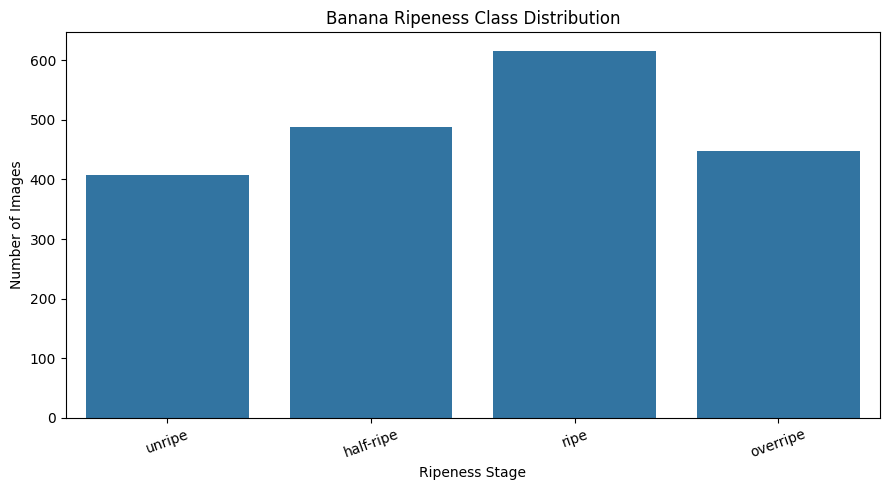

In [6]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="class_name", order=CLASS_NAMES)
plt.title("Banana Ripeness Class Distribution")
plt.xlabel("Ripeness Stage")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 3. Stratified train/validation/test split

The split is **70% training, 15% validation, and 15% test**. Stratification preserves the relative frequency of each ripeness class.

The split is performed before augmentation, so validation and test images remain untouched.


In [7]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

split_summary = pd.DataFrame({
    "train": train_df["class_name"].value_counts(),
    "validation": val_df["class_name"].value_counts(),
    "test": test_df["class_name"].value_counts()
}).reindex(CLASS_NAMES).fillna(0).astype(int)

display(split_summary)


Train: 1372
Validation: 294
Test: 294


,train,validation,test
class_name,,,
unripe,286,61,61
half-ripe,341,73,74
ripe,431,93,92
overripe,314,67,67


## 4. Class weights

Class weights are calculated from the training set. They are used for the standard classifier. The ordinal model uses the same training images but its threshold targets are handled directly by the ordinal loss.


In [8]:
classes = np.arange(NUM_CLASSES)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)
class_weights = dict(zip(classes, weights))
class_weights


{np.int64(0): np.float64(1.1993006993006994),
 np.int64(1): np.float64(1.0058651026392962),
 np.int64(2): np.float64(0.7958236658932715),
 np.int64(3): np.float64(1.0923566878980893)}

## 5. TensorFlow input pipeline

Images are resized to **224 × 224**, converted to RGB, and scaled to the range expected by the Keras ResNet152 preprocessing function.

Augmentation is applied only to training batches.


In [9]:
from tensorflow.keras.applications.resnet import preprocess_input

AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

def load_image(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image

def make_dataset(frame, target_mode="categorical", training=False):
    paths = frame["filepath"].values
    labels = frame["label"].values.astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(frame),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    def mapper(path, label):
        image = load_image(path)
        if training:
            image = data_augmentation(image, training=True)
        image = preprocess_input(image)

        if target_mode == "categorical":
            return image, label
        else:
            ordinal_target = tf.cast(
                tf.range(NUM_CLASSES - 1) < label,
                tf.float32
            )
            return image, ordinal_target

    ds = ds.map(mapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds_cat = make_dataset(train_df, "categorical", True)
val_ds_cat = make_dataset(val_df, "categorical", False)
test_ds_cat = make_dataset(test_df, "categorical", False)

train_ds_ord = make_dataset(train_df, "ordinal", True)
val_ds_ord = make_dataset(val_df, "ordinal", False)
test_ds_ord = make_dataset(test_df, "ordinal", False)


# Part 0 — Transfer learning with ImageNet-pretrained ResNet152

This model is added before the original experiments. It uses **ImageNet-pretrained ResNet152 weights** instead of training the entire network from random initialization.

Training happens in two stages:
1. Freeze the pretrained ResNet152 backbone and train the new classification head.
2. Unfreeze only the final backbone layers and fine-tune them with a smaller learning rate.

The existing dataset, train/validation/test split, preprocessing pipeline, categorical model, ordinal model, and remaining notebook cells are kept unchanged.

In [10]:
# Build a transfer-learning ResNet152 model
# The input pipeline already applies ResNet preprocessing.

def build_transfer_learning_model():
    inputs = keras.Input(shape=(*IMG_SIZE, 3))

    backbone = keras.applications.ResNet152(
        include_top=False,
        weights="imagenet",
        input_shape=(*IMG_SIZE, 3)
    )

    # Stage 1: keep pretrained feature extractor frozen
    backbone.trainable = False

    x = backbone(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(
        inputs,
        outputs,
        name="ResNet152_Transfer_Learning"
    )

    return model, backbone


transfer_model, transfer_backbone = build_transfer_learning_model()

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

transfer_model.summary()

234698864/234698864 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "ResNet152_Transfer_Learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet152 (Functional)          │ (None, 7, 7, 2048)     │    58,370,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,560,580 (227.21 MB)

 Trainable params: 1,185,540 (4.52 MB)

 Non-trainable params: 58,375,040 (222.68 MB)

## Transfer learning — Stage 1: train the classification head

The pretrained convolutional layers are frozen. Only the newly added classification head is trained in this stage.

In [11]:
TRANSFER_HEAD_EPOCHS = 10
TRANSFER_FINE_TUNE_EPOCHS = 20

transfer_head_callbacks = [
    keras.callbacks.ModelCheckpoint(
        MODEL_DIR / "resnet152_transfer_head_best.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max"
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    )
]

history_transfer_head = transfer_model.fit(
    train_ds_cat,
    validation_data=val_ds_cat,
    epochs=TRANSFER_HEAD_EPOCHS,
    class_weight=class_weights,
    callbacks=transfer_head_callbacks
)

Epoch 1/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 111s 807ms/step - accuracy: 0.5955 - loss: 1.1489 - val_accuracy: 0.6599 - val_loss: 0.7158 - learning_rate: 0.0010
Epoch 2/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 28s 322ms/step - accuracy: 0.6953 - loss: 0.8229 - val_accuracy: 0.7245 - val_loss: 0.6530 - learning_rate: 0.0010
Epoch 3/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 25s 287ms/step - accuracy: 0.7398 - loss: 0.6495 - val_accuracy: 0.7211 - val_loss: 0.5864 - learning_rate: 0.0010
Epoch 4/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 44s 318ms/step - accuracy: 0.7711 - loss: 0.5924 - val_accuracy: 0.7483 - val_loss: 0.6338 - learning_rate: 0.0010
Epoch 5/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 28s 323ms/step - accuracy: 0.7879 - loss: 0.5652 - val_accuracy: 0.7653 - val_loss: 0.5565 - learning_rate: 0.0010
Epoch 6/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 37s 273ms/step - accuracy: 0.7923 - loss: 0.5050 - val_accuracy: 0.7619 - val_loss: 0.5707 - learning_rate: 0.0010
Epoch 7/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step - accuracy: 0.8351 - loss: 0.

## Transfer learning — Stage 2: fine-tune the final ResNet152 layers

After the classification head has learned, the final 30 layers of ResNet152 are unfrozen. Earlier layers remain frozen to preserve general visual features and reduce overfitting. A smaller learning rate is used for fine-tuning.

In [12]:
# Unfreeze only the final 30 layers.
# Keep BatchNormalization layers frozen for more stable fine-tuning.
transfer_backbone.trainable = True

for layer in transfer_backbone.layers[:-30]:
    layer.trainable = False

for layer in transfer_backbone.layers[-30:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

transfer_fine_tune_callbacks = [
    keras.callbacks.ModelCheckpoint(
        MODEL_DIR / "resnet152_transfer_learning_best.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max"
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    )
]

history_transfer_fine = transfer_model.fit(
    train_ds_cat,
    validation_data=val_ds_cat,
    epochs=TRANSFER_FINE_TUNE_EPOCHS,
    class_weight=class_weights,
    callbacks=transfer_fine_tune_callbacks
)

Epoch 1/20
86/86 ━━━━━━━━━━━━━━━━━━━━ 90s 644ms/step - accuracy: 0.8681 - loss: 0.3402 - val_accuracy: 0.7789 - val_loss: 0.5351 - learning_rate: 1.0000e-05
Epoch 2/20
86/86 ━━━━━━━━━━━━━━━━━━━━ 29s 340ms/step - accuracy: 0.8717 - loss: 0.3079 - val_accuracy: 0.7925 - val_loss: 0.5125 - learning_rate: 1.0000e-05
Epoch 3/20
86/86 ━━━━━━━━━━━━━━━━━━━━ 41s 346ms/step - accuracy: 0.8856 - loss: 0.2879 - val_accuracy: 0.8197 - val_loss: 0.4389 - learning_rate: 1.0000e-05
Epoch 4/20
86/86 ━━━━━━━━━━━━━━━━━━━━ 25s 292ms/step - accuracy: 0.9016 - loss: 0.2525 - val_accuracy: 0.8027 - val_loss: 0.4993 - learning_rate: 1.0000e-05
Epoch 5/20
86/86 ━━━━━━━━━━━━━━━━━━━━ 48s 382ms/step - accuracy: 0.9038 - loss: 0.2414 - val_accuracy: 0.8503 - val_loss: 0.4270 - learning_rate: 1.0000e-05
Epoch 6/20
86/86 ━━━━━━━━━━━━━━━━━━━━ 26s 294ms/step - accuracy: 0.9140 - loss: 0.2193 - val_accuracy: 0.8469 - val_loss: 0.4358 - learning_rate: 1.0000e-05
Epoch 7/20
86/86 ━━━━━━━━━━━━━━━━━━━━ 25s 293ms/step - acc

In [14]:
def build_resnet152_backbone():
    return keras.applications.ResNet152(
        include_top=False,
        weights=None,
        input_shape=(*IMG_SIZE, 3)
    )

def ordinal_bce_loss(y_true, y_pred):
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    loss = -(
        y_true * tf.math.log(y_pred) +
        (1.0 - y_true) * tf.math.log(1.0 - y_pred)
    )
    return tf.reduce_mean(loss)

def build_ordinal_model():
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    backbone = build_resnet152_backbone()
    x = backbone(inputs, training=True)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES - 1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="ResNet152_Ordinal")

ordinal_model = build_ordinal_model()
ordinal_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=ordinal_bce_loss
)
ordinal_model.summary()

Model: "ResNet152_Ordinal"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet152 (Functional)          │ (None, 7, 7, 2048)     │    58,370,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,896,259 (224.67 MB)

 Trainable params: 58,744,835 (224.09 MB)

 Non-trainable params: 151,424 (591.50 KB)

## Transfer learning — learning curves

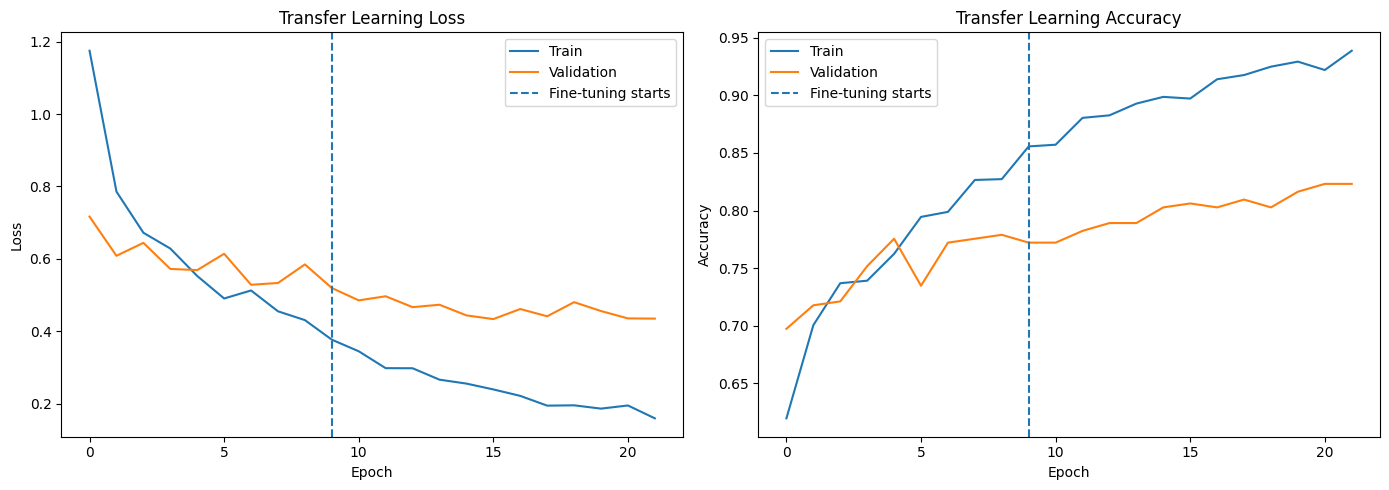

In [ ]:
transfer_train_accuracy = (
    history_transfer_head.history["accuracy"] +
    history_transfer_fine.history["accuracy"]
)
transfer_val_accuracy = (
    history_transfer_head.history["val_accuracy"] +
    history_transfer_fine.history["val_accuracy"]
)
transfer_train_loss = (
    history_transfer_head.history["loss"] +
    history_transfer_fine.history["loss"]
)
transfer_val_loss = (
    history_transfer_head.history["val_loss"] +
    history_transfer_fine.history["val_loss"]
)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(transfer_train_loss, label="Train")
ax[0].plot(transfer_val_loss, label="Validation")
ax[0].axvline(
    len(history_transfer_head.history["loss"]) - 1,
    linestyle="--",
    label="Fine-tuning starts"
)
ax[0].set_title("Transfer Learning Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()

ax[1].plot(transfer_train_accuracy, label="Train")
ax[1].plot(transfer_val_accuracy, label="Validation")
ax[1].axvline(
    len(history_transfer_head.history["accuracy"]) - 1,
    linestyle="--",
    label="Fine-tuning starts"
)
ax[1].set_title("Transfer Learning Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()

plt.tight_layout()
plt.show()

## Evaluate the transfer-learning model on the test set

The test set is used only after both training stages are complete.

19/19 ━━━━━━━━━━━━━━━━━━━━ 21s 629ms/step
Transfer Learning Accuracy: 0.8707
Transfer Learning MAE: 0.1361
\nClassification Report:
              precision    recall  f1-score   support

      unripe     0.9444    0.8361    0.8870        61
   half-ripe     0.8026    0.8243    0.8133        74
        ripe     0.8851    0.8370    0.8603        92
    overripe     0.8701    1.0000    0.9306        67

    accuracy                         0.8707       294
   macro avg     0.8756    0.8743    0.8728       294
weighted avg     0.8732    0.8707    0.8700       294



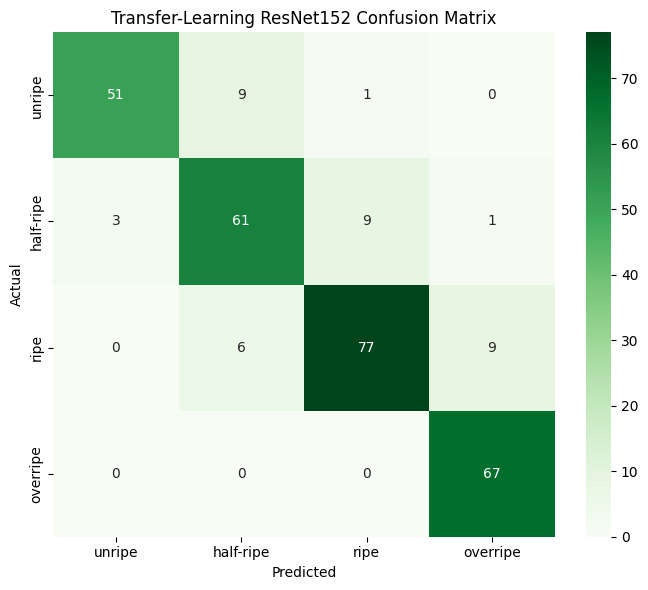

,Model,Accuracy,MAE
0,ResNet152 Transfer Learning,0.870748,0.136054


In [ ]:
transfer_prob = transfer_model.predict(test_ds_cat)
transfer_pred = np.argmax(transfer_prob, axis=1)
transfer_true = test_df["label"].values

transfer_accuracy = accuracy_score(transfer_true, transfer_pred)
transfer_mae = mean_absolute_error(transfer_true, transfer_pred)

print(f"Transfer Learning Accuracy: {transfer_accuracy:.4f}")
print(f"Transfer Learning MAE: {transfer_mae:.4f}")

print("\\nClassification Report:")
print(classification_report(
    transfer_true,
    transfer_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(
    confusion_matrix(
        transfer_true,
        transfer_pred,
        labels=np.arange(NUM_CLASSES)
    ),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title("Transfer-Learning ResNet152 Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

transfer_comparison = pd.DataFrame({
    "Model": ["ResNet152 Transfer Learning"],
    "Accuracy": [transfer_accuracy],
    "MAE": [transfer_mae]
})

display(transfer_comparison)

transfer_comparison.to_csv(
    MODEL_DIR / "transfer_learning_comparison.csv",
    index=False
)

transfer_model.save(
    MODEL_DIR / "resnet152_transfer_learning_final.keras"
)

In [ ]:
from google.colab import drive
import os

# 1. Connect your Google Drive (approve the pop-up permission prompt)
drive.mount('/content/drive')

# 2. Create a folder in your Google Drive
drive_dir = "/content/drive/MyDrive/Banana_Ripeness_Models"
os.makedirs(drive_dir, exist_ok=True)

# 3. Save the trained transfer learning model from memory directly to Drive
transfer_model.save(f"{drive_dir}/resnet152_transfer_learning_final.keras")

print("Transfer learning model successfully saved to Google Drive!")

Mounted at /content/drive
Transfer learning model successfully saved to Google Drive!


# Part A — Standard multiclass classification

The baseline predicts one of four classes with a softmax output:

`[Unripe, Half-ripe, Ripe, Overripe]`.


In [ ]:
def build_resnet152_backbone():
    return keras.applications.ResNet152(
        include_top=False,
        weights=None,
        input_shape=(*IMG_SIZE, 3)
    )

def build_categorical_model():
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    backbone = build_resnet152_backbone()
    x = backbone(inputs, training=True)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="ResNet152_Categorical")

categorical_model = build_categorical_model()

categorical_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

categorical_model.summary()


Model: "ResNet152_Categorical"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet152 (Functional)          │ (None, 7, 7, 2048)     │    58,370,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,896,516 (224.67 MB)

 Trainable params: 58,745,092 (224.09 MB)

 Non-trainable params: 151,424 (591.50 KB)

In [ ]:
categorical_callbacks = [
    keras.callbacks.ModelCheckpoint(
        MODEL_DIR / "resnet152_categorical_best.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max"
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="accuracy",
        mode="max",
        patience=6,
        restore_best_weights=True
    )
]

history_cat = categorical_model.fit(
    train_ds_cat,
    validation_data=val_ds_cat,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=categorical_callbacks
)


Epoch 1/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 311s 2s/step - accuracy: 0.3069 - loss: 1.7189 - val_accuracy: 0.2483 - val_loss: 1.5213 - learning_rate: 1.0000e-04
Epoch 2/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 50s 581ms/step - accuracy: 0.3717 - loss: 1.2918 - val_accuracy: 0.2075 - val_loss: 1.6833 - learning_rate: 1.0000e-04
Epoch 3/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 54s 622ms/step - accuracy: 0.4803 - loss: 1.0706 - val_accuracy: 0.2075 - val_loss: 2.3421 - learning_rate: 1.0000e-04
Epoch 4/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 571ms/step - accuracy: 0.5354 - loss: 0.9898
Epoch 4: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.
86/86 ━━━━━━━━━━━━━━━━━━━━ 59s 691ms/step - accuracy: 0.5364 - loss: 0.9894 - val_accuracy: 0.2619 - val_loss: 2.2690 - learning_rate: 1.0000e-04
Epoch 5/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 103s 943ms/step - accuracy: 0.5926 - loss: 0.8906 - val_accuracy: 0.5102 - val_loss: 1.0085 - learning_rate: 2.0000e-05
Epoch 6/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 75s 871ms/step - accuracy:

In [ ]:
import os

drive_dir = "/content/drive/MyDrive/Banana_Ripeness_Models"
os.makedirs(drive_dir, exist_ok=True)

categorical_model.save(f"{drive_dir}/resnet152_categorical_final.keras")
print("✅ Categorical model successfully saved to Google Drive!")

✅ Categorical model successfully saved to Google Drive!


## Categorical learning curves


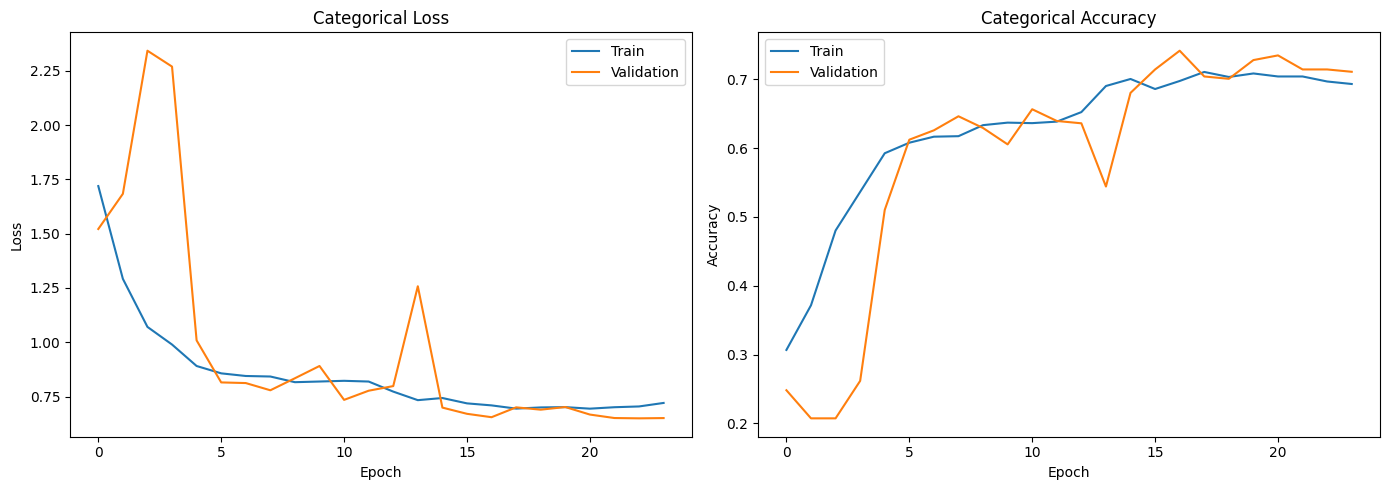

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(history_cat.history["loss"], label="Train")
ax[0].plot(history_cat.history["val_loss"], label="Validation")
ax[0].set_title("Categorical Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()

ax[1].plot(history_cat.history["accuracy"], label="Train")
ax[1].plot(history_cat.history["val_accuracy"], label="Validation")
ax[1].set_title("Categorical Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()

plt.tight_layout()
plt.show()


## Evaluate the categorical classifier


19/19 ━━━━━━━━━━━━━━━━━━━━ 27s 793ms/step
Categorical Accuracy: 0.7619
Categorical MAE: 0.2619

Classification Report:
              precision    recall  f1-score   support

      unripe     0.8594    0.9016    0.8800        61
   half-ripe     0.7627    0.6081    0.6767        74
        ripe     0.7292    0.7609    0.7447        92
    overripe     0.7200    0.8060    0.7606        67

    accuracy                         0.7619       294
   macro avg     0.7678    0.7691    0.7655       294
weighted avg     0.7625    0.7619    0.7593       294



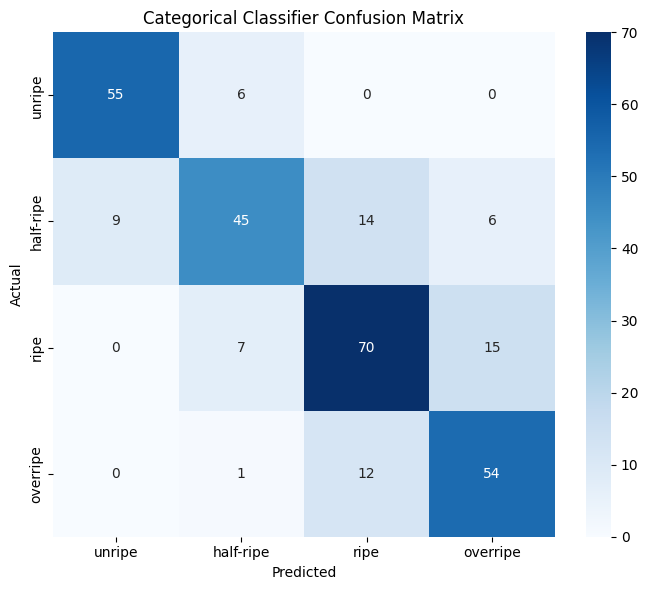

In [ ]:
cat_prob = categorical_model.predict(test_ds_cat)
cat_pred = np.argmax(cat_prob, axis=1)
cat_true = test_df["label"].values

cat_accuracy = accuracy_score(cat_true, cat_pred)
cat_mae = mean_absolute_error(cat_true, cat_pred)

print(f"Categorical Accuracy: {cat_accuracy:.4f}")
print(f"Categorical MAE: {cat_mae:.4f}")

print("\nClassification Report:")
print(classification_report(
    cat_true,
    cat_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(
    confusion_matrix(cat_true, cat_pred, labels=np.arange(NUM_CLASSES)),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title("Categorical Classifier Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


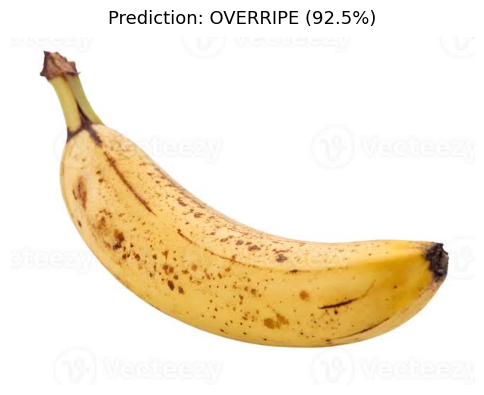

IMAGE: image.jpg
--- Categorical Softmax Probabilities ---
  Unripe      :   0.00%
  Half-ripe   :   0.02%
  Ripe        :   7.47%
  Overripe    :  92.51%
  --> Final Prediction: Overripe


In [ ]:
def predict_single_image(image_path):
    # 1. Load and display image
    raw_img = Image.open(image_path).convert('RGB')

    # 2. Preprocess (224x224, ResNet preprocess_input)
    img_resized = raw_img.resize(IMG_SIZE)
    img_array = np.array(img_resized, dtype=np.float32)
    img_preprocessed = preprocess_input(img_array)
    img_batch = np.expand_dims(img_preprocessed, axis=0)

    # 3. Categorical Model Prediction
    cat_probs = categorical_model.predict(img_batch, verbose=0)[0]
    cat_pred_idx = np.argmax(cat_probs)
    cat_class = CLASS_NAMES[cat_pred_idx]

    # 4. Display visualization and outputs
    plt.figure(figsize=(6, 6))
    plt.imshow(raw_img)
    plt.axis("off")
    plt.title(f"Prediction: {cat_class.upper()} ({cat_probs[cat_pred_idx]*100:.1f}%)", fontsize=13, pad=10)
    plt.show()

    print("=" * 45)
    print(f"IMAGE: {image_path}")
    print("=" * 45)
    print("--- Categorical Softmax Probabilities ---")
    for name, p in zip(CLASS_NAMES, cat_probs):
        print(f"  {name.capitalize():<12}: {p * 100:6.2f}%")
    print(f"  --> Final Prediction: {cat_class.capitalize()}")
    print("=" * 45)

# Test with your already-uploaded file
predict_single_image("image.jpg")

# Part B — Ordinal regression

Ripeness is ordered:

**Unripe < Half-ripe < Ripe < Overripe**

Instead of treating the four classes as unrelated categories, ordinal regression learns three cumulative thresholds:

- `P(y > Unripe)`
- `P(y > Half-ripe)`
- `P(y > Ripe)`

The target encodings are:

- Unripe → `[0, 0, 0]`
- Half-ripe → `[1, 0, 0]`
- Ripe → `[1, 1, 0]`
- Overripe → `[1, 1, 1]`


In [15]:
def ordinal_bce_loss(y_true, y_pred):
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    loss = -(
        y_true * tf.math.log(y_pred) +
        (1.0 - y_true) * tf.math.log(1.0 - y_pred)
    )
    return tf.reduce_mean(loss)

def build_ordinal_model():
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    backbone = build_resnet152_backbone()
    x = backbone(inputs, training=True)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES - 1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="ResNet152_Ordinal")

ordinal_model = build_ordinal_model()

ordinal_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=ordinal_bce_loss
)

ordinal_model.summary()


Model: "ResNet152_Ordinal"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet152 (Functional)          │ (None, 7, 7, 2048)     │    58,370,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,896,259 (224.67 MB)

 Trainable params: 58,744,835 (224.09 MB)

 Non-trainable params: 151,424 (591.50 KB)

In [16]:
ordinal_callbacks = [
    keras.callbacks.ModelCheckpoint(
        MODEL_DIR / "resnet152_ordinal_best.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min"
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    )
]

history_ord = ordinal_model.fit(
    train_ds_ord,
    validation_data=val_ds_ord,
    epochs=EPOCHS,
    callbacks=ordinal_callbacks
)


Epoch 1/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 298s 2s/step - loss: 0.6287 - val_loss: 0.6078 - learning_rate: 1.0000e-04
Epoch 2/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 47s 543ms/step - loss: 0.4173 - val_loss: 0.7069 - learning_rate: 1.0000e-04
Epoch 3/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 48s 554ms/step - loss: 0.3329 - val_loss: 0.8387 - learning_rate: 1.0000e-04
Epoch 4/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - loss: 0.3269
Epoch 4: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.
86/86 ━━━━━━━━━━━━━━━━━━━━ 82s 549ms/step - loss: 0.3219 - val_loss: 0.7215 - learning_rate: 1.0000e-04
Epoch 5/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 92s 665ms/step - loss: 0.2926 - val_loss: 0.3871 - learning_rate: 2.0000e-05
Epoch 6/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 78s 915ms/step - loss: 0.2747 - val_loss: 0.3010 - learning_rate: 2.0000e-05
Epoch 7/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 59s 651ms/step - loss: 0.2690 - val_loss: 0.2341 - learning_rate: 2.0000e-05
Epoch 8/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 47s 542ms/step - loss: 0.2

In [20]:
from google.colab import drive
import os

# 1. Remove the local dummy folder that blocked mounting
!rm -rf /content/drive

# 2. Mount your actual Google Drive (approve the pop-up)
drive.mount('/content/drive')

# 3. Save the trained model from memory directly to your Drive
drive_dir = "/content/drive/MyDrive/Banana_Ripeness_Models"
os.makedirs(drive_dir, exist_ok=True)
saved_path = f"{drive_dir}/resnet152_ordinal_final.keras"
ordinal_model.save(saved_path)

# 4. Verify it saved properly (~225 MB)
print("Exists in Drive:", os.path.exists(saved_path))
print("File size (MB):", round(os.path.getsize(saved_path) / (1024 * 1024), 2))

Mounted at /content/drive
Exists in Drive: True
File size (MB): 675.1


## Ordinal learning curves


In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(history_ord.history["loss"], label="Train")
plt.plot(history_ord.history["val_loss"], label="Validation")
plt.title("Ordinal Regression Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()


## Convert cumulative ordinal probabilities into a class prediction

For four classes, the model outputs three probabilities corresponding to the thresholds.

The predicted class is the number of thresholds whose probability is at least 0.5.


In [ ]:
ord_prob = ordinal_model.predict(test_ds_ord)
ord_pred = (ord_prob >= 0.5).sum(axis=1)
ord_true = test_df["label"].values

ord_accuracy = accuracy_score(ord_true, ord_pred)
ord_mae = mean_absolute_error(ord_true, ord_pred)

print(f"Ordinal Accuracy: {ord_accuracy:.4f}")
print(f"Ordinal MAE: {ord_mae:.4f}")

print("\nClassification Report:")
print(classification_report(
    ord_true,
    ord_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(
    confusion_matrix(ord_true, ord_pred, labels=np.arange(NUM_CLASSES)),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title("Ordinal Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


# Final comparison

Accuracy measures exact class agreement.

MAE measures the average absolute distance between the true and predicted ripeness level:

- 0 = exact class
- 1 = one ripeness stage away
- 2 = two stages away
- 3 = three stages away

Because ripeness is ordinal, MAE is particularly informative: predicting `Ripe` for `Half-ripe` is a smaller ordinal error than predicting `Overripe` for `Unripe`.


In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "ResNet152 Transfer Learning",
        "ResNet152 Categorical (from scratch)",
        "ResNet152 Ordinal (from scratch)"
    ],
    "Accuracy": [
        transfer_accuracy,
        cat_accuracy,
        ord_accuracy
    ],
    "MAE": [
        transfer_mae,
        cat_mae,
        ord_mae
    ]
})

display(comparison.sort_values("Accuracy", ascending=False))

comparison.to_csv(
    MODEL_DIR / "model_comparison.csv",
    index=False
)

plt.figure(figsize=(10, 5))
plt.bar(comparison["Model"], comparison["Accuracy"])
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy Comparison — All Three Models")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(comparison["Model"], comparison["MAE"])
plt.ylabel("Mean Absolute Error")
plt.title("Test MAE Comparison — All Three Models")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## Error-distance analysis


In [ ]:
transfer_errors = np.abs(transfer_true - transfer_pred)
cat_errors = np.abs(cat_true - cat_pred)
ord_errors = np.abs(ord_true - ord_pred)

error_summary = pd.DataFrame({
    "Error Distance": np.arange(NUM_CLASSES),
    "Transfer Learning Count": [
        np.sum(transfer_errors == d) for d in range(NUM_CLASSES)
    ],
    "Categorical Count": [
        np.sum(cat_errors == d) for d in range(NUM_CLASSES)
    ],
    "Ordinal Count": [
        np.sum(ord_errors == d) for d in range(NUM_CLASSES)
    ]
})

display(error_summary)

plt.figure(figsize=(10, 5))
x = np.arange(NUM_CLASSES)
width = 0.25

plt.bar(
    x - width,
    error_summary["Transfer Learning Count"],
    width,
    label="Transfer Learning"
)

plt.bar(
    x,
    error_summary["Categorical Count"],
    width,
    label="Categorical"
)

plt.bar(
    x + width,
    error_summary["Ordinal Count"],
    width,
    label="Ordinal"
)

plt.xticks(x, [str(i) for i in range(NUM_CLASSES)])
plt.xlabel("Absolute Ripeness Error")
plt.ylabel("Number of Test Images")
plt.title("Prediction Error Distance — All Three Models")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras.applications.resnet import preprocess_input

def predict_single_image(image_path):
    # 1. Load and display image
    raw_img = Image.open(image_path).convert('RGB')

    # 2. Preprocess to match training pipeline (224x224, ResNet preprocess_input)
    img_resized = raw_img.resize(IMG_SIZE)
    img_array = np.array(img_resized, dtype=np.float32)
    img_preprocessed = preprocess_input(img_array)
    img_batch = np.expand_dims(img_preprocessed, axis=0)

    # 3. Categorical Model Prediction
    cat_probs = categorical_model.predict(img_batch, verbose=0)[0]
    cat_pred_idx = np.argmax(cat_probs)
    cat_class = CLASS_NAMES[cat_pred_idx]

    # 4. Ordinal Model Prediction
    # Counts thresholds where sigmoid output >= 0.5
    ord_probs = ordinal_model.predict(img_batch, verbose=0)[0]
    ord_pred_idx = int(np.sum(ord_probs >= 0.5))
    ord_class = CLASS_NAMES[ord_pred_idx]

    # 5. Display visualization and outputs
    plt.figure(figsize=(6, 6))
    plt.imshow(raw_img)
    plt.axis("off")
    plt.title(f"Categorical: {cat_class.upper()} | Ordinal: {ord_class.upper()}", fontsize=13, pad=10)
    plt.show()

    print("=" * 45)
    print(f"IMAGE: {image_path}")
    print("=" * 45)
    print("--- Categorical Softmax Probabilities ---")
    for name, p in zip(CLASS_NAMES, cat_probs):
        print(f"  {name.capitalize():<12}: {p * 100:6.2f}%")
    print(f"  --> Final Prediction: {cat_class.capitalize()}\n")

    print("--- Ordinal Threshold Probabilities ---")
    threshold_names = [f"P(Ripeness > {name.capitalize()})" for name in CLASS_NAMES[:-1]]
    for t_name, p in zip(threshold_names, ord_probs):
        passed = "✓" if p >= 0.5 else "✗"
        print(f"  {t_name:<25}: {p:6.4f} [{passed}]")
    print(f"  --> Final Prediction: {ord_class.capitalize()}")
    print("=" * 45)

# Trigger file upload dialog
print("Upload a banana image from your device:")
uploaded = files.upload()

for filename in uploaded.keys():
    predict_single_image(filename)

# Save the final models


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Change MODEL_DIR to a folder inside your Google Drive
MODEL_DIR = Path("/content/drive/MyDrive/Banana_Ripeness_Models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Reproducibility checklist

Before training:

- Put the original BananaID ripeness images under `./dataset`.
- Confirm the four folders/classes are **Unripe, Half-ripe, Ripe, Overripe**.
- Keep the original images only; do not place augmented copies into the dataset used for splitting.
- Confirm that the class distribution printed by the notebook is reasonable.

Experiment settings:

- Model: **ResNet152**
- Weights: **None — trained from scratch**
- Input: **224 × 224 RGB**
- Maximum epochs: **50**
- Batch size: **16**
- Optimizer: **Adam**
- Learning rate: **1e-4**
- Split: **70/15/15**, stratified
- Metrics: **Accuracy and MAE**
- Baseline: **Softmax cross-entropy**
- Proposed approach: **Ordinal cumulative-threshold loss**

## Research note

This notebook is now aligned to a genuine ripeness-classification dataset rather than a generic fruit-recognition dataset. BananaID has four ordered ripeness stages and 1,960 original ripeness images, making it a more direct fit for an ordinal-regression experiment. citeturn0search1
